# Органическая активация продукта и экосистемный LTV

Одна исходная панель `df`, три представления для **DiD**, **DML/IRM** и
**IPCW**, а также известные истинные эффекты. Ноутбук показывает генерацию и
подготовку данных; оцениватели эффектов здесь не обучаются.

По умолчанию создаём **5 000 клиентов**, чтобы быстро пройти пример.
Для полного benchmark замените `N_CLIENTS` на `50_000`. Запускайте ячейки сверху
вниз в Python-окружении с установленным Causalis.

[Подробное описание DGP и API](organic_activation.md).


In [1]:
from pathlib import Path
import sys

# Позволяет запускать ноутбук как из корня репозитория, так и из notebooks/examples.
repo_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "causalis").is_dir() and (p / "pyproject.toml").is_file()),
    None,
)
if repo_root is not None and str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from causalis.dgp import generate_organic_activation_data
from causalis.dgp.organic_activation import (
    make_did_pair,
    make_dml_view,
    make_ipcw_view,
    summarize_data,
    validate_data,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 30)
pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.figsize": (12, 4), "font.size": 10})


## 1. Генерация одной панели

Клиент появляется в месяце `entry_period` и наблюдается до конца панели.
Первая активация возможна после одного полного месяца наблюдения.
В начале месяца сначала измеряется `l_activity_pre`, затем принимается решение
об активации и формируется `ltv_monthly`. Treatment влияет только на outcome.

Для активации в $g$ горизонт $H$ содержит месяцы $g,\ldots,g+H-1$.
Event time $h=0$ — первый treated-месяц; $g-1$ — последний полный untreated-месяц.

- `df` содержит наблюдаемые признаки, design-поля и outcomes.
- `oracle` хранит скрытые величины и контрфактические траектории отдельно.
- `metadata` описывает разрешённые признаки, estimands и предпосылки.


In [2]:
N_CLIENTS = 5_000
N_PERIODS = 24
HORIZON = 6
G = 10
SEED = 42
SCENARIO = "baseline"

df, oracle, metadata = generate_organic_activation_data(
    n_clients=N_CLIENTS,
    n_periods=N_PERIODS,
    horizon=HORIZON,
    scenario=SCENARIO,
    seed=SEED,
)

display(df.head(8))
print(f"Клиентов: {df['client_id'].nunique():,}; строк: {len(df):,}")


,client_id,period,date,entry_period,tenure_months,n_pre_periods_available,first_activation_period,activation_now,treated,eligible_to_activate,event_time,x_income,x_salary,x_segment,x_digital,x_noise_1,x_noise_2,l_activity_pre,ltv_monthly,ltv_cumulative
0,0,8,2024-09-01,8,0,0,14,False,False,False,-6,115677.67,0,0,0.12,0.55,0.94,1.36,381.74,381.74
1,0,9,2024-10-01,8,1,1,14,False,False,True,-5,115677.67,0,0,0.12,0.55,0.94,-0.61,-100.86,280.88
2,0,10,2024-11-01,8,2,2,14,False,False,True,-4,115677.67,0,0,0.12,0.55,0.94,0.02,350.35,631.23
3,0,11,2024-12-01,8,3,3,14,False,False,True,-3,115677.67,0,0,0.12,0.55,0.94,-1.02,364.35,995.58
4,0,12,2025-01-01,8,4,4,14,False,False,True,-2,115677.67,0,0,0.12,0.55,0.94,-1.66,343.58,1339.16
5,0,13,2025-02-01,8,5,5,14,False,False,True,-1,115677.67,0,0,0.12,0.55,0.94,0.42,654.62,1993.78
6,0,14,2025-03-01,8,6,6,14,True,True,True,0,115677.67,0,0,0.12,0.55,0.94,0.81,976.31,2970.09
7,0,15,2025-04-01,8,7,7,14,False,True,False,1,115677.67,0,0,0.12,0.55,0.94,1.10,693.03,3663.12


Клиентов: 5,000; строк: 97,516


## 2. Проверки структуры и поддержки сравнений

Проверяем поглощающую активацию, eligibility, накопление LTV, отсутствие
эффекта до активации и воспроизведение factual/контрфактических траекторий.
`support_*` — информационные флаги: в очень маленькой случайной выборке
некоторые группы могут отсутствовать.

Месячный вклад может быть отрицательным, поэтому накопленный LTV не обязан
возрастать. Отсутствующую pre-history не заменяем нулями.


In [3]:
checks = validate_data(df, oracle, metadata)
diagnostics = summarize_data(df, oracle, metadata)

display(pd.Series(checks, name="passed").to_frame())
display(pd.Series(diagnostics["overview"], name="value").to_frame())
print(f"Отрицательных месячных вкладов: {df['ltv_monthly'].lt(0).mean():.1%}")


,passed
unique_client_period,True
client_ids,True
constant_client_design,True
administrative_followup,True
history_lengths,True
...,...
feature_isolation,True
metadata_consistency,True
support_treated,True
support_never_treated,True


,value
scenario,baseline
n_clients,5000
n_rows,97516
never_activated_fraction,0.31
n_main_cohort_treated,1329


Отрицательных месячных вкладов: 5.4%


In [4]:
display(diagnostics["control_support"].query("g == @G"))
display(diagnostics["dml_later_activation"].query("g == @G"))
display(diagnostics["hazard_quantiles"].rename("true_hazard").to_frame())


,g,t,event_time,n_treated,n_controls,n_censored_controls
54,10,10,0,221,3671,0
55,10,11,1,221,3443,228
56,10,12,2,221,3212,459
57,10,13,3,221,2983,688
58,10,14,4,221,2755,916
59,10,15,5,221,2543,1128


,g,n_controls,n_later_activators,fraction_later_activation,n_activations_within_horizon,fraction_activation_within_horizon
9,10,3671,2121,0.58,1128,0.31


,true_hazard
0.00,0.01
0.01,0.02
0.05,0.03
0.25,0.04
0.50,0.06
0.75,0.08
0.95,0.12
0.99,0.15
1.00,0.24


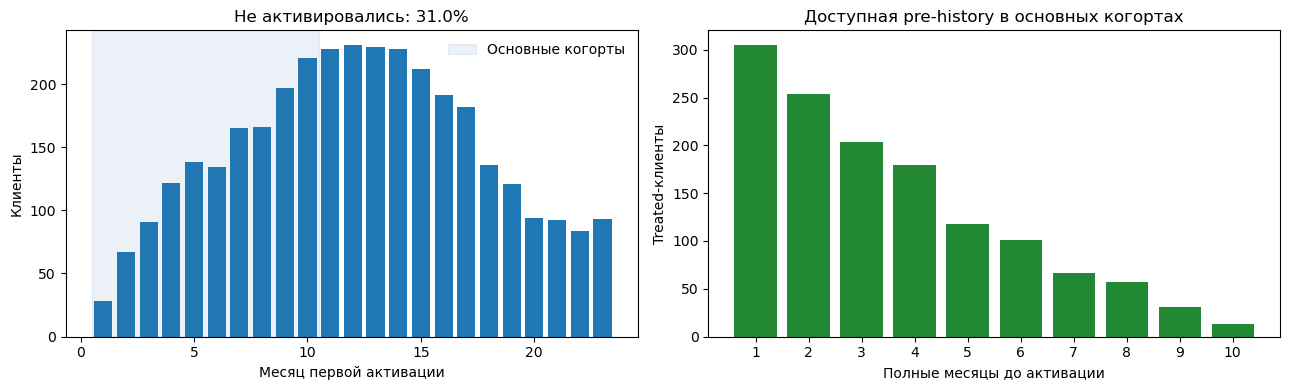

In [5]:
clients = df.drop_duplicates("client_id")
activation_counts = (
    clients["first_activation_period"]
    .value_counts()
    .reindex(range(1, N_PERIODS), fill_value=0)
)
pre_counts = diagnostics["pre_history_counts"].reindex(range(1, 11), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(activation_counts.index.to_numpy(dtype=int), activation_counts.to_numpy())
axes[0].axvspan(0.5, 10.5, color="#4477AA", alpha=0.10, label="Основные когорты")
axes[0].set(xlabel="Месяц первой активации", ylabel="Клиенты",
            title=f"Не активировались: {clients['first_activation_period'].isna().mean():.1%}")
axes[0].legend(frameon=False)
axes[1].bar(pre_counts.index, pre_counts.values, color="#228833")
axes[1].set(xlabel="Полные месяцы до активации", ylabel="Treated-клиенты",
            title="Доступная pre-history в основных когортах")
axes[1].set_xticks(range(1, 11))
fig.tight_layout()
display(fig)
plt.close(fig)


## 3. Два разных oracle benchmark

| Параметр | Сравнение среди фактически активировавшихся в $g$ | Дизайн |
|---|---|---|
| `ATT_no_activation` | Начать в $g$ против отсутствия активации на всём горизонте | Месячный staggered DiD; baseline-adjusted IPCW |
| `ATT_defer_natural` | Начать в $g$ против пропуска только месяца $g$, затем естественная активация | Baseline DML/IRM с поздними активаторами в контроле |

В режиме «пропустить $g$» будущая активация пересчитывается с теми же внешними
инновациями. Oracle — реализованные эффекты в сгенерированной treated-выборке.
Вес каждой основной когорты равен её доле в общей численности treated и
**одинаков на всех event months**.


In [6]:
att = diagnostics["att_aggregate"]
display(metadata["cohort_weights"])
display(att)

np.testing.assert_allclose(
    att["cumulative_no_activation"], att["att_no_activation"].cumsum()
)
np.testing.assert_allclose(
    att["cumulative_defer_natural"], att["att_defer_natural"].cumsum()
)


,g,n_treated,weight
0,1,28,0.02
1,2,67,0.05
2,3,91,0.07
3,4,122,0.09
4,5,138,0.10
5,6,134,0.10
6,7,165,0.12
7,8,166,0.12
8,9,197,0.15
9,10,221,0.17


,event_time,att_no_activation,att_defer_natural,cumulative_no_activation,cumulative_defer_natural,monthly_estimand_gap,cumulative_estimand_gap
0,0,93.95,93.95,93.95,93.95,0.00,0.00
1,1,160.07,152.88,254.03,246.84,7.19,7.19
2,2,207.12,188.64,461.14,435.48,18.47,25.66
3,3,241.10,208.84,702.24,644.32,32.25,57.91
4,4,266.13,218.61,968.37,862.93,47.52,105.44
5,5,285.05,220.68,1253.41,1083.61,64.36,169.80


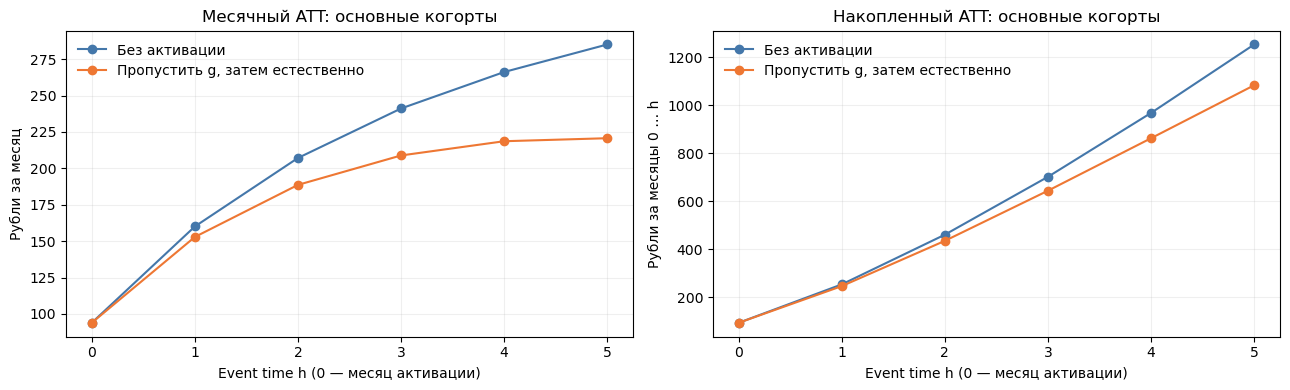

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
curves = (
    ("att_no_activation", "cumulative_no_activation", "Без активации", "#4477AA"),
    ("att_defer_natural", "cumulative_defer_natural", "Пропустить g, затем естественно", "#EE7733"),
)
for monthly, cumulative, label, color in curves:
    axes[0].plot(att["event_time"], att[monthly], marker="o", label=label, color=color)
    axes[1].plot(att["event_time"], att[cumulative], marker="o", label=label, color=color)
for ax in axes:
    ax.set_xlabel("Event time h (0 — месяц активации)")
    ax.set_xticks(range(HORIZON))
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
axes[0].set(title="Месячный ATT: основные когорты", ylabel="Рубли за месяц")
axes[1].set(title="Накопленный ATT: основные когорты", ylabel="Рубли за месяцы 0 … h")
fig.tight_layout()
display(fig)
plt.close(fig)


Посмотрим на контрфактические outcomes одного клиента, у которого естественная
активация после пропуска `g` успела повлиять на outcome в пределах горизонта.
`y_start`, `y_no_activation` и `y_defer_natural` — oracle-поля; они не входят в X.


In [8]:
individual = oracle["individual_effects"]
changed_alternative = individual.loc[
    (individual["att_no_activation"] - individual["att_defer_natural"]).abs() > 0
]
if not individual.empty:
    example_client = int(
        (changed_alternative if not changed_alternative.empty else individual)
        .iloc[0]["client_id"]
    )
    print("client_id:", example_client,
          "; активация после пропуска g:", oracle["skip_activation_period"].loc[example_client])
    display(individual.loc[
        individual["client_id"].eq(example_client),
        ["client_id", "g", "event_time", "y_start", "y_no_activation", "y_defer_natural",
         "att_no_activation", "att_defer_natural"],
    ])
else:
    print("В основных когортах нет treated-клиентов; увеличьте N_CLIENTS.")


client_id: 1464 ; активация после пропуска g: 6


,client_id,g,event_time,y_start,y_no_activation,y_defer_natural,att_no_activation,att_defer_natural
12,1464,1,0,1090.89,976.58,976.58,114.31,114.31
13,1464,1,1,1363.75,1169.00,1169.00,194.75,194.75
14,1464,1,2,1284.12,1032.13,1032.13,251.99,251.99
15,1464,1,3,1893.09,1599.76,1599.76,293.33,293.33
16,1464,1,4,1935.25,1611.46,1611.46,323.79,323.79
17,1464,1,5,1304.74,957.94,1072.25,346.80,232.49


## 4. Представление для DiD

Одна строка — клиент с парой **месячных** outcomes в $g-1$ и $t$.
Treated имеют $G_i=g$; контроль — $G_i>t$ или отсутствие активации до конца
панели. Клиенты, вошедшие в $g-1$, включаются: у них есть один полный pre-месяц.

Для гарантии DiD в `latent_level_confounding` используем статические X и
`entry_period`. Постоянный месячный скрытый уровень $U_i$ сокращается при
вычитании месячных outcomes. Для накопленного LTV такая гарантия не переносится.
Шумовые лаги outcome не добавляем к этому conditioning set автоматически.


In [9]:
T = G + HORIZON - 1
df_did = make_did_pair(df, g=G, t=T)
X_did = df_did.loc[:, df_did.attrs["model_features"]]

display(df_did[["client_id", "g", "t", "d", "y_pre", "y_post", "delta_y"]].head(8))
print("Estimand:", df_did.attrs["estimand"])
print("Признаки:", X_did.columns.tolist())
print("Клиентов по группам:", df_did["d"].value_counts().sort_index().to_dict())


,client_id,g,t,d,y_pre,y_post,delta_y
0,1,10,15,0,1306.57,1260.76,-45.81
1,2,10,15,0,30.99,449.94,418.95
2,3,10,15,0,-10.42,275.20,285.62
3,7,10,15,0,667.24,1302.88,635.64
4,9,10,15,0,880.21,895.07,14.86
5,12,10,15,0,332.96,1119.69,786.74
6,13,10,15,0,59.51,882.53,823.02
7,15,10,15,0,1250.69,1773.88,523.19


Estimand: ATT_no_activation
Признаки: ['x_income', 'x_salary', 'x_segment', 'x_digital', 'x_noise_1', 'x_noise_2', 'entry_period']
Клиентов по группам: {0: 2543, 1: 221}


## 5. Представление для DML / IRM ATT

Одна строка — eligible-клиент перед решением в $g$.
`d=1` означает активацию именно в $g$, а `y_ltv_h` — сумму фактических денежных
вкладов за $g,\ldots,g+H-1$. Будущие активаторы сохраняют исходную метку `d=0`.

Benchmark этой выборки — **`ATT_defer_natural`**. Предрешенческое `L_g`
входит в X; в observed-time-varying сценарии оно необходимо для exchangeability.
Будущая дата активации ниже используется только для иллюстрации состава контроля.


In [10]:
df_dml = make_dml_view(df, g=G, horizon=HORIZON)
X_dml = df_dml.loc[:, df_dml.attrs["model_features"]]
display(df_dml.head(8))
print("Estimand:", df_dml.attrs["estimand"])
print("Признаки:", X_dml.columns.tolist())

# Дата будущей активации присоединяется только к диагностическому представлению.
dml_timing = df_dml[["client_id", "d", "y_ltv_h"]].merge(
    clients[["client_id", "first_activation_period"]],
    on="client_id", validate="one_to_one",
)
later_controls = dml_timing.loc[
    dml_timing["d"].eq(0)
    & dml_timing["first_activation_period"].between(G + 1, G + HORIZON - 1).fillna(False)
]
print(f"Контролей с активацией внутри горизонта: {len(later_controls):,}")
display(later_controls.head(8))


,client_id,baseline_period,d,x_income,x_salary,x_segment,x_digital,x_noise_1,x_noise_2,entry_period,l_activity_pre,y_ltv_h
0,0,10,0,115677.67,0,0,0.12,0.55,0.94,8,0.02,3382.24
1,1,10,0,129431.96,1,0,0.45,-0.30,0.58,5,0.52,8252.75
2,2,10,0,91568.05,0,1,0.69,-0.49,1.38,9,0.04,1224.71
3,3,10,0,46958.40,0,1,0.76,-0.66,-0.53,2,-0.22,2581.37
4,6,10,0,40502.18,0,1,0.80,1.19,-0.41,8,0.06,5661.06
5,7,10,0,88144.33,1,1,0.21,-0.91,-0.63,8,0.68,6688.61
6,8,10,0,106491.03,1,0,0.58,-1.62,0.47,9,1.10,7317.97
7,9,10,0,95995.90,0,0,0.68,2.73,-0.23,8,1.78,5876.25


Estimand: ATT_defer_natural
Признаки: ['x_income', 'x_salary', 'x_segment', 'x_digital', 'x_noise_1', 'x_noise_2', 'entry_period', 'l_activity_pre']
Контролей с активацией внутри горизонта: 1,128


,client_id,d,y_ltv_h,first_activation_period
0,0,0,3382.24,14
4,6,0,5661.06,15
6,8,0,7317.97,13
8,10,0,5251.20,11
11,14,0,2412.80,11
13,16,0,5668.94,14
19,22,0,7171.28,12
21,24,0,4565.71,11


## 6. Последовательный trial с искусственным цензурированием

Одна строка — клиент × месяц follow-up. Baseline-признаки заморожены с
префиксом `b_`; текущая `l_activity_pre` измерена до решения текущего месяца.

У baseline-контроля цензурирование происходит в начале первой последующей
активации. Строка события остаётся для обучения censoring hazard, но её
outcome уже treated: `outcome_usable=False`. Все более поздние outcomes этого
контроля тоже не используются. У baseline-treated искусственного цензурирования нет.


In [11]:
df_ipcw = make_ipcw_view(df, g=G, horizon=HORIZON)
ipcw_features = df_ipcw.attrs["model_features"]

X_ipcw_assignment = df_ipcw.loc[
    df_ipcw["followup_month"].eq(0), ipcw_features["baseline"]
]
X_ipcw_censoring = df_ipcw.loc[
    df_ipcw["at_risk_of_censoring"], ipcw_features["censoring"]
]
ipcw_usable_outcomes = df_ipcw.loc[df_ipcw["outcome_usable"]]

print("Estimand:", df_ipcw.attrs["estimand"])
print("Baseline propensity features:", ipcw_features["baseline"])
print("Censoring features:", ipcw_features["censoring"])
print(f"Строк follow-up: {len(df_ipcw):,}; пригодных outcomes: {len(ipcw_usable_outcomes):,}")

censor_events = df_ipcw.loc[df_ipcw["censor_now"]]
early_events = censor_events.loc[censor_events["followup_month"].lt(HORIZON - 1)]
if not censor_events.empty:
    censored_client = int((early_events if not early_events.empty else censor_events).iloc[0]["client_id"])
    display(df_ipcw.loc[
        df_ipcw["client_id"].eq(censored_client),
        ["client_id", "period", "followup_month", "baseline_d",
         "b_l_activity_pre", "l_activity_pre", "at_risk_of_censoring",
         "censor_now", "uncensored_through_t", "outcome_usable", "ltv_monthly"],
    ])
else:
    print("В этой выборке нет событий искусственного цензурирования.")


Estimand: ATT_no_activation
Baseline propensity features: ['b_x_income', 'b_x_salary', 'b_x_segment', 'b_x_digital', 'b_x_noise_1', 'b_x_noise_2', 'b_entry_period', 'b_l_activity_pre']
Censoring features: ['x_income', 'x_salary', 'x_segment', 'x_digital', 'x_noise_1', 'x_noise_2', 'entry_period', 'period', 'tenure_months', 'l_activity_pre']
Строк follow-up: 23,352; пригодных outcomes: 19,933


,client_id,period,followup_month,baseline_d,b_l_activity_pre,l_activity_pre,at_risk_of_censoring,censor_now,uncensored_through_t,outcome_usable,ltv_monthly
0,0,10,0,0,0.02,0.02,False,False,True,True,350.35
1,0,11,1,0,0.02,-1.02,True,False,True,True,364.35
2,0,12,2,0,0.02,-1.66,True,False,True,True,343.58
3,0,13,3,0,0.02,0.42,True,False,True,True,654.62
4,0,14,4,0,0.02,0.81,True,True,False,False,976.31
5,0,15,5,0,0.02,1.10,False,False,False,False,693.03


IPCW исправляет информативную позднюю активацию **в дополнение к** исходному
confounding. Для оставшегося untreated-контроля ATT-вес имеет структуру

$$
w_{ig,t}=\frac{e_g(\mathcal H_{ig})}{1-e_g(\mathcal H_{ig})}
\prod_{s=g+1}^{t}\frac{1}{P(A_{is}=0\mid G_i\geq s,\mathcal H_{is})}.
$$

В $t=g$ произведение равно 1: baseline assignment не учитывается повторно.
Censoring-модель обучается только на `at_risk_of_censoring`; outcomes берутся
только из `outcome_usable`. Для объединения нескольких trials cross-fitting
и bootstrap группируются по `client_id`.


In [12]:
view_sizes = pd.DataFrame([
    {"view": "DiD pair", "rows": len(df_did), "clients": df_did["client_id"].nunique(),
     "benchmark": df_did.attrs["estimand"]},
    {"view": "DML baseline", "rows": len(df_dml), "clients": df_dml["client_id"].nunique(),
     "benchmark": df_dml.attrs["estimand"]},
    {"view": "IPCW follow-up", "rows": len(df_ipcw), "clients": df_ipcw["client_id"].nunique(),
     "benchmark": df_ipcw.attrs["estimand"]},
])
display(view_sizes)
assert len(df_ipcw) == len(df_dml) * HORIZON
assert len(df) == diagnostics["overview"]["n_rows"]

# Все X задаются allowlist, а не выбором всех числовых столбцов.
for features in [X_did.columns, X_dml.columns, X_ipcw_assignment.columns, X_ipcw_censoring.columns]:
    unprefixed = {name.removeprefix("b_") for name in features}
    assert unprefixed.isdisjoint({
        "client_id", "first_activation_period", "event_time", "ltv_monthly",
        "ltv_cumulative", "U", "V", "hazard", "y_no_activation",
    })


,view,rows,clients,benchmark
0,DiD pair,2764,2764,ATT_no_activation
1,DML baseline,3892,3892,ATT_defer_natural
2,IPCW follow-up,23352,3892,ATT_no_activation


### Oracle для показанных сравнений в когорте G

Графики выше агрегируют **все основные когорты**. Три представления в этом
примере относятся только к `G=10`, поэтому будущие оценки по ним нужно
сравнивать с oracle этой когорты, а не с агрегированной кривой. Для DiD-пары
берём месячный эффект в `T`; для DML и суммарного IPCW — эффект за весь горизонт.


In [13]:
cohort_att = oracle["att_by_cohort"].query("g == @G").sort_values("event_time")
display(cohort_att)
monthly_target = cohort_att.loc[cohort_att["event_time"].eq(T - G)].iloc[0]
horizon_target = cohort_att.loc[cohort_att["event_time"].eq(HORIZON - 1)].iloc[0]
cohort_benchmarks = pd.DataFrame([
    {"view": "DiD pair", "g": G, "target": "Monthly ATT_no_activation at T",
     "oracle_rub": monthly_target["att_no_activation"]},
    {"view": "DML baseline", "g": G, "target": "Horizon ATT_defer_natural",
     "oracle_rub": horizon_target["cumulative_defer_natural"]},
    {"view": "IPCW horizon sum", "g": G, "target": "Horizon ATT_no_activation",
     "oracle_rub": horizon_target["cumulative_no_activation"]},
])
display(cohort_benchmarks)


,g,event_time,n_treated,weight,att_no_activation,att_defer_natural,cumulative_no_activation,cumulative_defer_natural
54,10,0,221,0.17,93.42,93.42,93.42,93.42
55,10,1,221,0.17,159.15,149.27,252.57,242.68
56,10,2,221,0.17,205.93,180.43,458.50,423.12
57,10,3,221,0.17,239.71,196.86,698.21,619.98
58,10,4,221,0.17,264.60,204.88,962.82,824.86
59,10,5,221,0.17,283.41,206.24,1246.23,1031.09


,view,g,target,oracle_rub
0,DiD pair,10,Monthly ATT_no_activation at T,283.41
1,DML baseline,10,Horizon ATT_defer_natural,1031.09
2,IPCW horizon sum,10,Horizon ATT_no_activation,1246.23


## 7. Сценарии и предпосылки

Состоятельность ниже относится к правильно заданным nuisance-моделям,
соответствующему estimand и достаточной поддержке. Ортогонализация сама по себе
не устраняет скрытый confounding.

| Сценарий | DiD на месячных outcomes, X + entry | DML с X + entry + L_g | IPCW с baseline- и censoring-корректировкой |
|---|---|---|---|
| `baseline` | Идентификация | Идентификация | Идентификация |
| `latent_level_confounding` | Идентификация | Нет гарантии | Нет гарантии |
| `observed_timevarying_confounding` | Нет гарантии | Идентификация | Идентификация |
| `hidden_timevarying_confounding` | Нет гарантии | Нет гарантии | Нет гарантии |
| `null_effect` | Эффект ровно ноль | Эффект ровно ноль | Эффект ровно ноль |
| `weak_overlap` | Формальная идентификация; слабый overlap | То же | То же; произведение весов может быть нестабильным |

Для IPCW Markov-состояние позволяет использовать текущие X, entry, календарный
период, tenure и L_t. Квантили **истинного** hazard доступны только в oracle.
В `weak_overlap` вероятности близки к 0/1; генератор не обрезает веса и не
удаляет клиентов автоматически.


In [14]:
display(metadata["scenario_table"].loc[
    metadata["scenario_table"]["scenario"].eq(SCENARIO),
    ["method", "estimand", "features", "assumptions", "identified", "limitation"],
])


,method,estimand,features,assumptions,identified,limitation
0,did,ATT_no_activation,"static X, entry_period; monthly outcomes; no o...","Conditional parallel trends, no anticipation, ...",True,
1,dml,ATT_defer_natural,"static X, entry_period, predecision L_g",Baseline exchangeability and overlap; natural ...,True,
2,ipcw,ATT_no_activation,"baseline X, entry_period, L_g; censoring X, en...","Baseline and sequential exchangeability, consi...",True,


### Необязательно: компактная диагностика всех сценариев

По умолчанию блок выключен, чтобы создавать только одну основную панель.
Установите `RUN_SCENARIO_COMPARISON=True`, чтобы последовательно сгенерировать
маленькие панели и сохранить только сводную таблицу.

Изменение истинного ATT между сценариями может отражать другой состав treated.
Эта таблица не проверяет смещение или состоятельность оценивателей: оцениватели
здесь не запускаются.


In [15]:
RUN_SCENARIO_COMPARISON = False

if RUN_SCENARIO_COMPARISON:
    scenario_rows = []
    for scenario_name in metadata["model_features"]:
        scenario_df, scenario_oracle, scenario_metadata = generate_organic_activation_data(
            n_clients=2_000, n_periods=N_PERIODS, horizon=HORIZON,
            scenario=scenario_name, seed=SEED,
        )
        validate_data(scenario_df, scenario_oracle, scenario_metadata)
        summary = summarize_data(scenario_df, scenario_oracle, scenario_metadata)
        final_att = summary["att_aggregate"].iloc[-1]
        if scenario_name == "null_effect":
            assert scenario_oracle["potential_outcomes"]["effect_factual"].eq(0).all()
            assert final_att[["cumulative_no_activation", "cumulative_defer_natural"]].eq(0).all()
        scenario_rows.append({
            "scenario": scenario_name,
            "never_activated": summary["overview"]["never_activated_fraction"],
            "hazard_min": summary["hazard_quantiles"].iloc[0],
            "hazard_max": summary["hazard_quantiles"].iloc[-1],
            "ATT_no_activation_H": final_att["cumulative_no_activation"],
            "ATT_defer_natural_H": final_att["cumulative_defer_natural"],
        })
        del scenario_df, scenario_oracle, scenario_metadata
    scenario_comparison = pd.DataFrame(scenario_rows)
    display(scenario_comparison)
else:
    print("Сравнение сценариев выключено. Основная панель доступна в df.")


Сравнение сценариев выключено. Основная панель доступна в df.


## Дальнейший анализ

`df`, `oracle`, `metadata`, `df_did`, `df_dml` и `df_ipcw` остаются доступны в
памяти. Для каждого оценивателя используйте соответствующий benchmark;
для DiD накапливайте месячные ATT с фиксированными весами когорт.

- [Callaway–Sant’Anna: Difference-in-Differences with Multiple Time Periods](https://arxiv.org/abs/1803.09015)
- [Hernán et al.: Specifying a target trial](https://pubmed.ncbi.nlm.nih.gov/27237061/)
- [Полное описание генератора](organic_activation.md)
